# Step 10 — external test on KNHANES (Korea), baseline

Train on NHANES only, test on KNHANES 2014 and 2016. This is the reference for anything that later uses KNHANES in training.

- **Features:** k114, the 114 features KNHANES has in both 2014 and 2016 (`docs/knhanes_mapping.csv`), in the NHANES definitions (`nhanes/knhanes.py`, compared in `data_analysis/03_knhanes_vs_nhanes.ipynb`).
- **Training:** all 7 NHANES cycles, 2005–2018.
- **Models:** elastic net and XGBoost, as in step 1 (`nhanes/loco.py`). Hyper-parameters are chosen by leave-one-cycle-out over the 7 NHANES cycles; KNHANES is not used for any choice.
- **Test:** KNHANES 2014 and 2016 separately (their labs and diet were measured differently, see data_analysis/03 section 6), and both years pooled. Outcome PHQ-9 ≥ 10.
- **Reference:** step 9 k114, the same features in leave-one-cycle-out within NHANES. The matching NHANES cycles are 2013–14 and 2015–16.

**Metrics:** AUROC (primary), with a 95% bootstrap interval (1,000 resamples of people). Also AUROC with the KNHANES survey weight `wt_itvex`, AUPRC and Brier score, plus calibration. Both models are trained with class weights (balanced / `scale_pos_weight`), so their probabilities sit above the true rate even within NHANES. Calibration is therefore read against the same models' NHANES predictions (step 9), not against the diagonal.

**Output:** `$NHANES_WORK/modeling/step10_knhanes_external/`, containing `predictions.csv.gz`, `metrics.csv`, `chosen_params.json` and `report.txt`.

`RUN = True` retrains (a few minutes on 4 threads) and needs the KNHANES files (`KNHANES_DATA`, see `nhanes/knhanes.py`). `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False  # True: retrain and overwrite $NHANES_WORK/modeling/step10_knhanes_external
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
OUT = RESULTS / "step10_knhanes_external"
REF = RESULTS / "step9_knhanes_features" / "k114"
mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv")
K114 = list(mapping.feature[mapping.years == "both"])
print(len(K114), "features")

114 features


## Run

In [2]:
if RUN:
    from nhanes import knhanes
    from nhanes.loco import (FEAT, LOGREG_GRID, NOT_FEATURES, XGB_GRID, fit_logreg, fit_xgb, grid,
                             logreg_matrix, metrics, tune)
    OUT.mkdir(parents=True, exist_ok=True)
    nh = pd.read_csv(FEAT / "features_2005_2018.csv.gz", usecols=NOT_FEATURES + K114)
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    kr = knhanes.load()
    cycles = sorted(nh.cycle.unique())
    Xtr, Xte = nh[K114], kr[K114]
    preds, chosen = [], {}
    for model, g in [("logreg", LOGREG_GRID), ("xgboost", XGB_GRID)]:
        params, inner = tune(model, nh, cycles, dic, grid(g))
        if model == "logreg":
            A, B = logreg_matrix(Xtr, Xte, dic)
            prob = fit_logreg(A, nh.depression, params).predict_proba(B)[:, 1]
        else:
            fit_p = {k: v for k, v in params.items() if k != "n_estimators"}
            m = fit_xgb(Xtr, nh.depression, None, None, fit_p, n_estimators=params["n_estimators"])
            prob = m.predict_proba(Xte)[:, 1]
        chosen[model] = {**params, "inner_auroc": round(inner, 4)}
        preds.append(pd.DataFrame({"id": kr.id, "cycle": kr.cycle, "model": model,
                                   "depression": kr.depression, "weight": kr.wt_itvex, "prob": prob}))
        print(model, chosen[model], flush=True)
    pred = pd.concat(preds, ignore_index=True)
    pred.to_csv(OUT / "predictions.csv.gz", index=False)
    (OUT / "chosen_params.json").write_text(json.dumps(chosen, indent=1))

    rng = np.random.default_rng(42)
    rows = []
    for (model, test), g in [*pred.groupby(["model", "cycle"]),
                             *[((m, "KNHANES 2014+2016"), g) for m, g in pred.groupby("model")]]:
        y, p = g.depression.to_numpy(), g.prob.to_numpy()
        boot = []
        for _ in range(1000):
            i = rng.integers(0, len(y), len(y))
            if y[i].min() != y[i].max():
                boot.append(roc_auc_score(y[i], p[i]))
        rows.append({"model": model, "test": test, **metrics(y, p, g.weight),
                     "auroc_lo": np.percentile(boot, 2.5), "auroc_hi": np.percentile(boot, 97.5)})
    met = pd.DataFrame(rows)
    met.to_csv(OUT / "metrics.csv", index=False)
    lines = ["train: NHANES 2005-2018 (7 cycles), k114 features; test: KNHANES; outcome PHQ-9 >= 10", "",
             "chosen hyper-parameters (leave-one-cycle-out within NHANES):", json.dumps(chosen), "",
             met.round(3).to_string(index=False)]
    (OUT / "report.txt").write_text("\n".join(lines) + "\n")

## Results

In [3]:
print((OUT / "report.txt").read_text())

train: NHANES 2005-2018 (7 cycles), k114 features; test: KNHANES; outcome PHQ-9 >= 10

chosen hyper-parameters (leave-one-cycle-out within NHANES):
{"logreg": {"C": 0.01, "l1_ratio": 0.5, "inner_auroc": 0.8341}, "xgboost": {"max_depth": 3, "min_child_weight": 1, "n_estimators": 230, "inner_auroc": 0.8347}}

  model              test  auroc  auroc_weighted  auprc  brier     n  prevalence  auroc_lo  auroc_hi
 logreg      KNHANES 2014  0.806           0.806  0.319  0.129  4852       0.070     0.782     0.830
 logreg      KNHANES 2016  0.849           0.851  0.389  0.135  5666       0.062     0.829     0.872
xgboost      KNHANES 2014  0.811           0.808  0.306  0.142  4852       0.070     0.786     0.834
xgboost      KNHANES 2016  0.841           0.841  0.344  0.147  5666       0.062     0.820     0.865
 logreg KNHANES 2014+2016  0.826           0.826  0.354  0.132 10518       0.066     0.809     0.843
xgboost KNHANES 2014+2016  0.825           0.822  0.323  0.145 10518       0.066     

External AUROC against the same features within NHANES (step 9 k114, leave-one-cycle-out). "NHANES, mean of 7 cycles" is the step 9 headline number. The two matching cycles are listed separately.

In [4]:
met = pd.read_csv(OUT / "metrics.csv")
ref = pd.read_csv(REF / "metrics.csv")
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
rows = []
for model in NAMES:
    r = ref[ref.model == model].set_index("test_cycle")
    rows += [{"model": NAMES[model], "test": "NHANES, mean of 7 cycles (step 9)", "auroc": r.auroc.mean()},
             {"model": NAMES[model], "test": "NHANES 2013-14 (step 9)", "auroc": r.auroc["2013-14"]},
             {"model": NAMES[model], "test": "NHANES 2015-16 (step 9)", "auroc": r.auroc["2015-16"]}]
    for _, e in met[met.model == model].iterrows():
        rows.append({"model": NAMES[model], "test": e.test, "auroc": e.auroc,
                     "95% CI": f"{e.auroc_lo:.3f}-{e.auroc_hi:.3f}", "auroc_weighted": e.auroc_weighted,
                     "auprc": e.auprc, "prevalence": e.prevalence})
comp = pd.DataFrame(rows).set_index(["model", "test"])
display(comp.round(3))
for model in NAMES:
    m = met[met.model == model].set_index("test").auroc
    r = ref[ref.model == model].set_index("test_cycle").auroc
    print(f"{NAMES[model]}: KNHANES 2014 - NHANES 2013-14 = {m['KNHANES 2014'] - r['2013-14']:+.3f}; "
          f"KNHANES 2016 - NHANES 2015-16 = {m['KNHANES 2016'] - r['2015-16']:+.3f}; "
          f"pooled KNHANES - NHANES mean = {m['KNHANES 2014+2016'] - r.mean():+.3f}")

auroc       95% CI  \
model       test                                                    
elastic net NHANES, mean of 7 cycles (step 9)  0.834          NaN   
            NHANES 2013-14 (step 9)            0.837          NaN   
            NHANES 2015-16 (step 9)            0.835          NaN   
            KNHANES 2014                       0.806  0.782-0.830   
            KNHANES 2016                       0.849  0.829-0.872   
            KNHANES 2014+2016                  0.826  0.809-0.843   
XGBoost     NHANES, mean of 7 cycles (step 9)  0.833          NaN   
            NHANES 2013-14 (step 9)            0.833          NaN   
            NHANES 2015-16 (step 9)            0.837          NaN   
            KNHANES 2014                       0.811  0.786-0.834   
            KNHANES 2016                       0.841  0.820-0.865   
            KNHANES 2014+2016                  0.825  0.808-0.842   

                                               auroc_weighted  auprc  \
model       test                                                       
elastic net NHANES, mean of 7 cycles (step 9)             NaN    NaN   
            NHANES 2013-14 (step 9)                       NaN    NaN   
            NHANES 2015-16 (step 9)                       NaN    NaN   
            KNHANES 2014                                0.806  0.319   
            KNHANES 2016                                0.851  0.389   
            KNHANES 2014+2016                           0.826  0.354   
XGBoost     NHANES, mean of 7 cycles (step 9)             NaN    NaN   
            NHANES 2013-14 (step 9)                       NaN    NaN   
            NHANES 2015-16 (step 9)                       NaN    NaN   
            KNHANES 2014                                0.808  0.306   
            KNHANES 2016                                0.841  0.344   
            KNHANES 2014+2016                           0.822  0.323   

                                               prevalence  
model       test                                           
elastic net NHANES, mean of 7 cycles (step 9)         NaN  
            NHANES 2013-14 (step 9)                   NaN  
            NHANES 2015-16 (step 9)                   NaN  
            KNHANES 2014                            0.070  
            KNHANES 2016                            0.062  
            KNHANES 2014+2016                       0.066  
XGBoost     NHANES, mean of 7 cycles (step 9)         NaN  
            NHANES 2013-14 (step 9)                   NaN  
            NHANES 2015-16 (step 9)                   NaN  
            KNHANES 2014                            0.070  
            KNHANES 2016                            0.062  
            KNHANES 2014+2016                       0.066

elastic net: KNHANES 2014 - NHANES 2013-14 = -0.031; KNHANES 2016 - NHANES 2015-16 = +0.015; pooled KNHANES - NHANES mean = -0.008
XGBoost: KNHANES 2014 - NHANES 2013-14 = -0.023; KNHANES 2016 - NHANES 2015-16 = +0.005; pooled KNHANES - NHANES mean = -0.008


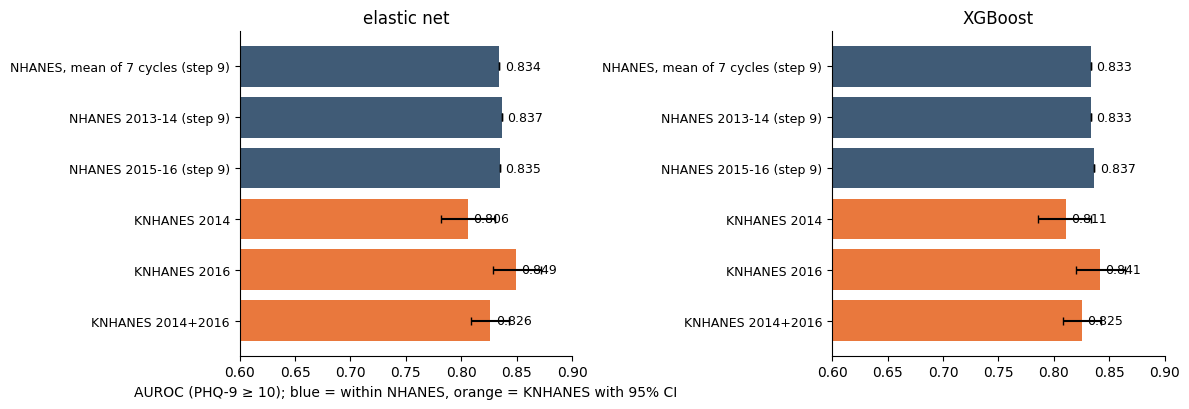

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, model in zip(axes, NAMES):
    s = comp.loc[NAMES[model], "auroc"]
    lo = met[met.model == model].set_index("test")
    err = [[0] * 3 + list(s.iloc[3:] - lo.auroc_lo.reindex(s.index[3:])),
           [0] * 3 + list(lo.auroc_hi.reindex(s.index[3:]) - s.iloc[3:])]
    colors = ["#405B76"] * 3 + ["#E9783D"] * (len(s) - 3)
    ax.barh(range(len(s))[::-1], s, xerr=err, color=colors, capsize=3)
    ax.set_yticks(range(len(s))[::-1], s.index, fontsize=9)
    for i, v in zip(range(len(s))[::-1], s):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0.6, 0.9)
    ax.set_title(NAMES[model])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_xlabel("AUROC (PHQ-9 ≥ 10); blue = within NHANES, orange = KNHANES with 95% CI")
plots.show()

## Calibration

Predicted against observed rate, in ten bins of predicted probability. Orange is KNHANES (both years). Blue is the same model's out-of-cycle predictions within NHANES (step 9 k114). Both curves sit below the diagonal because of the class weights, so the comparison that matters is between the two curves.

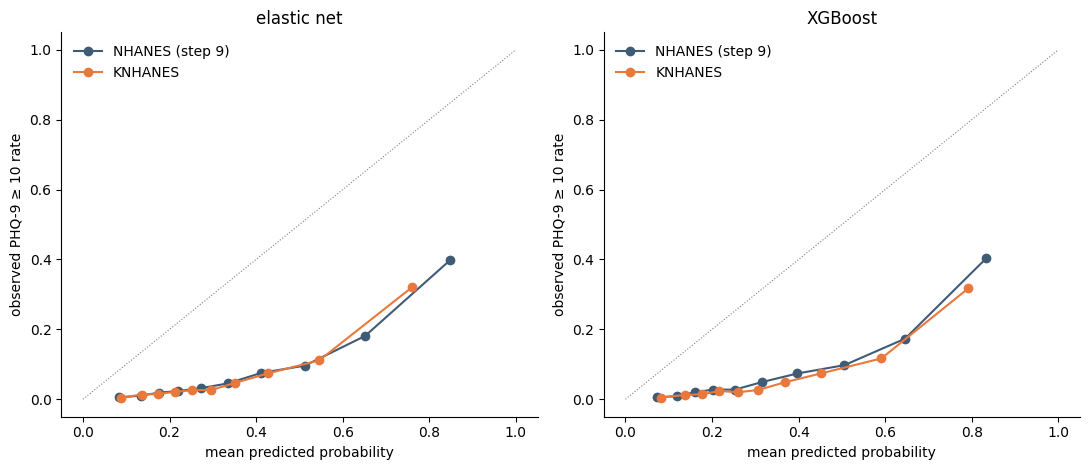

mean predicted  observed rate  \
model       data                                             
elastic net NHANES (step 9)           0.365          0.089   
            KNHANES                   0.324          0.066   
XGBoost     NHANES (step 9)           0.351          0.089   
            KNHANES                   0.338          0.066   

                             observed rate, top 10% of predictions  
model       data                                                    
elastic net NHANES (step 9)                                  0.399  
            KNHANES                                          0.320  
XGBoost     NHANES (step 9)                                  0.403  
            KNHANES                                          0.317

In [6]:
ref_pred = pd.read_csv(REF / "predictions.csv.gz")
pred = pd.read_csv(OUT / "predictions.csv.gz")


def calib(g, bins=10):
    q = pd.qcut(g.prob, bins, duplicates="drop")
    return g.groupby(q, observed=True).agg(pred=("prob", "mean"), obs=("depression", "mean"), n=("prob", "size"))


fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
rows = []
for ax, model in zip(axes, NAMES):
    for name, g, color in [("NHANES (step 9)", ref_pred[ref_pred.model == model], "#405B76"),
                           ("KNHANES", pred[pred.model == model], "#E9783D")]:
        c = calib(g)
        ax.plot(c.pred, c.obs, "o-", color=color, label=name)
        rows.append({"model": NAMES[model], "data": name, "mean predicted": g.prob.mean(),
                     "observed rate": g.depression.mean(),
                     "observed rate, top 10% of predictions": g.depression[g.prob >= g.prob.quantile(0.9)].mean()})
    ax.plot([0, 1], [0, 1], color="grey", lw=0.8, ls=":")
    ax.set_xlabel("mean predicted probability")
    ax.set_ylabel("observed PHQ-9 ≥ 10 rate")
    ax.set_title(NAMES[model])
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plots.show()
display(pd.DataFrame(rows).set_index(["model", "data"]).round(3))